In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [6]:
df = pd.read_csv('2019.csv')
df.head()

,Overall rank,Country or region,Score,GDP per capita,Social support,Healthy life expectancy,Freedom to make life choices,Generosity,Perceptions of corruption
0,1,Finland,7.769,1.340,1.587,0.986,0.596,0.153,0.393
1,2,Denmark,7.600,1.383,1.573,0.996,0.592,0.252,0.410
2,3,Norway,7.554,1.488,1.582,1.028,0.603,0.271,0.341
3,4,Iceland,7.494,1.380,1.624,1.026,0.591,0.354,0.118
4,5,Netherlands,7.488,1.396,1.522,0.999,0.557,0.322,0.298


In [7]:
print('Shape:', df.shape)
print('---')
print('Columns:', df.columns.tolist())
print('---')
print('Missing values:')
print(df.isnull().sum())

Shape: (156, 9)
---
Columns: ['Overall rank', 'Country or region', 'Score', 'GDP per capita', 'Social support', 'Healthy life expectancy', 'Freedom to make life choices', 'Generosity', 'Perceptions of corruption']
---
Missing values:
Overall rank                    0
Country or region               0
Score                           0
GDP per capita                  0
Social support                  0
Healthy life expectancy         0
Freedom to make life choices    0
Generosity                      0
Perceptions of corruption       0
dtype: int64


In [8]:
df.describe().round(2)

,Overall rank,Score,GDP per capita,Social support,Healthy life expectancy,Freedom to make life choices,Generosity,Perceptions of corruption
count,156.00,156.00,156.00,156.00,156.00,156.00,156.00,156.00
mean,78.50,5.41,0.91,1.21,0.73,0.39,0.18,0.11
std,45.18,1.11,0.40,0.30,0.24,0.14,0.10,0.09
min,1.00,2.85,0.00,0.00,0.00,0.00,0.00,0.00
25%,39.75,4.54,0.60,1.06,0.55,0.31,0.11,0.05
50%,78.50,5.38,0.96,1.27,0.79,0.42,0.18,0.09
75%,117.25,6.18,1.23,1.45,0.88,0.51,0.25,0.14
max,156.00,7.77,1.68,1.62,1.14,0.63,0.57,0.45


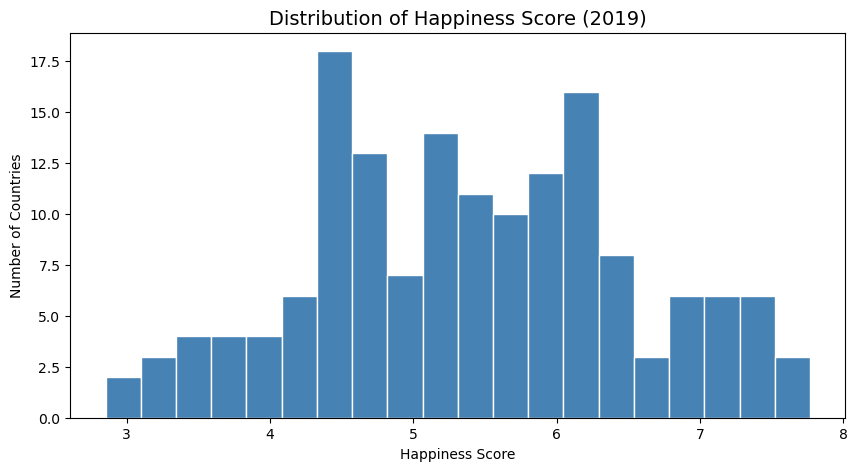

In [10]:
plt.figure(figsize=(10,5))
plt.hist(df['Score'], bins=20,color='steelblue',edgecolor='white')
plt.title('Distribution of Happiness Score (2019)', fontsize=14)
plt.xlabel('Happiness Score')
plt.ylabel('Number of Countries')

plt.show()

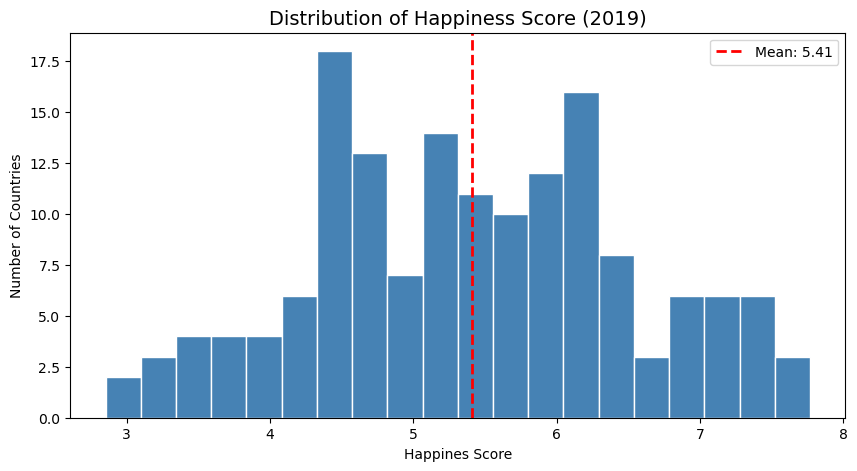

In [11]:
plt.figure(figsize=(10, 5))
plt.hist(df['Score'], bins=20, color='steelblue', edgecolor='white')

plt.axvline(df['Score'].mean(), color='red', linestyle='--', linewidth=2, label=f'Mean: {df["Score"].mean():.2f}')

plt.title('Distribution of Happiness Score (2019)', fontsize=14)
plt.xlabel('Happines Score')
plt.ylabel('Number of Countries')
plt.legend()

plt.show()

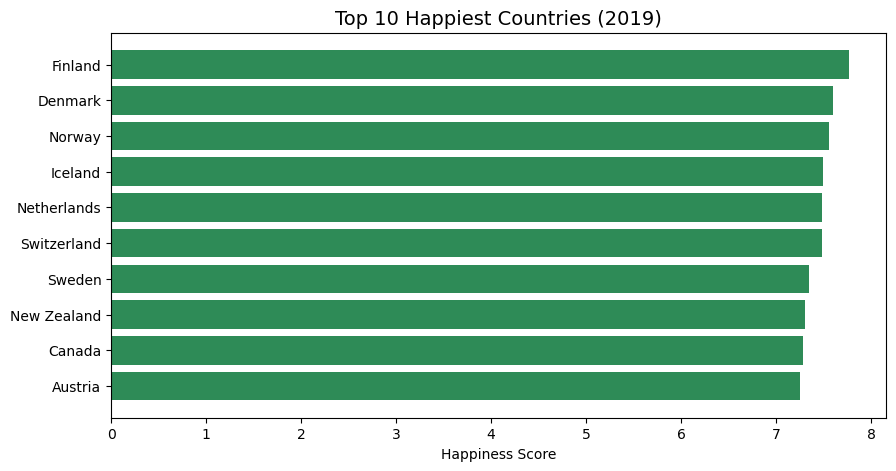

In [13]:
top10 = df.sort_values('Score', ascending=False).head(10)

plt.figure(figsize=(10,5))

plt.barh(top10['Country or region'], top10['Score'], color='seagreen')

plt.gca().invert_yaxis()

plt.title('Top 10 Happiest Countries (2019)', fontsize=14)
plt.xlabel('Happiness Score')

plt.show()

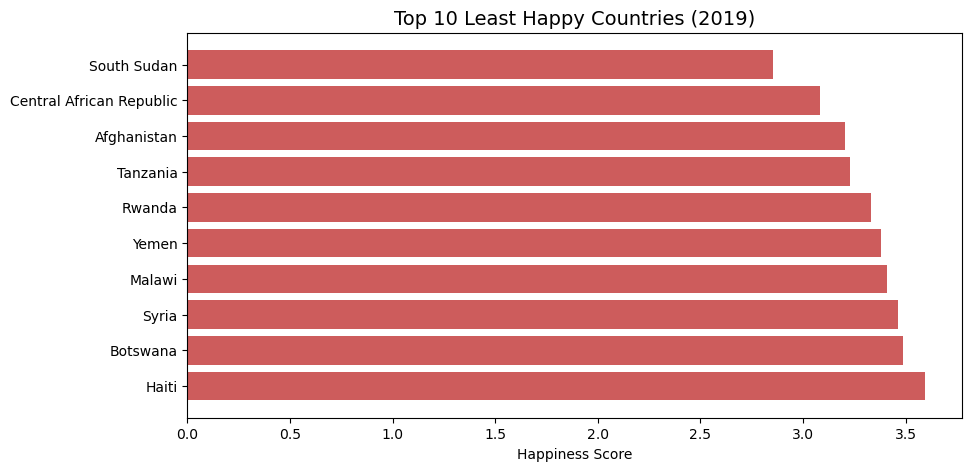

In [14]:
bottom10 = df.sort_values('Score', ascending=True).head(10)

plt.figure(figsize=(10,5))

plt.barh(bottom10['Country or region'], bottom10['Score'], color='indianred')

plt.gca().invert_yaxis()

plt.title('Top 10 Least Happy Countries (2019)', fontsize=14)
plt.xlabel('Happiness Score')

plt.show()

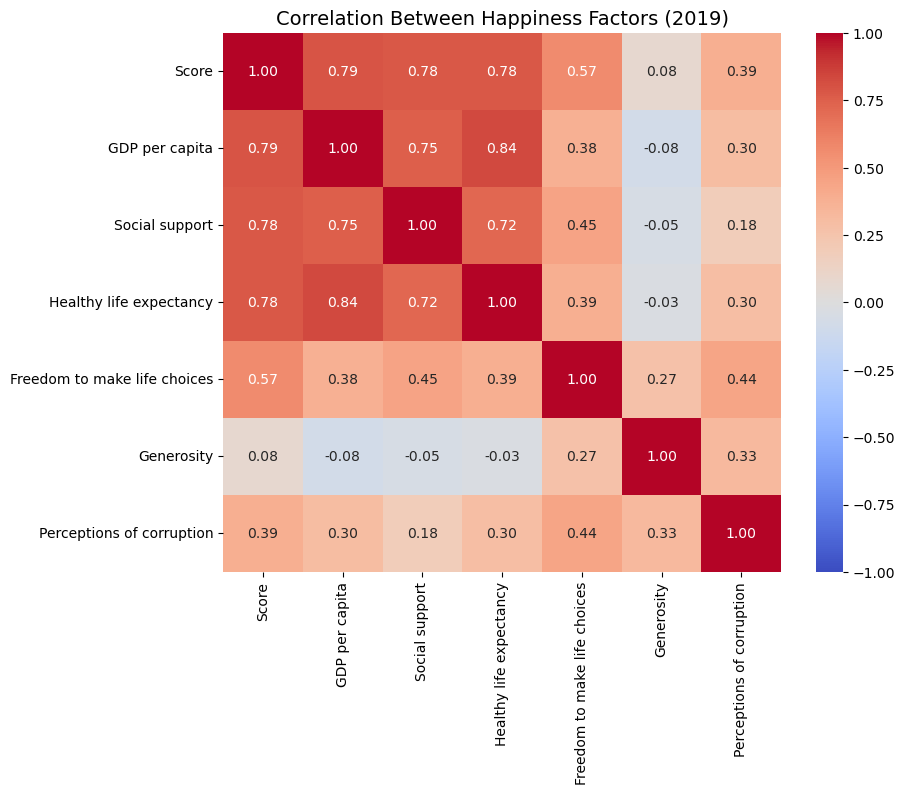

In [18]:
corr = df.drop(columns=['Overall rank', 'Country or region']).corr()

plt.figure(figsize=(9, 7))

sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)

plt.title('Correlation Between Happiness Factors (2019)', fontsize=14)


plt.show()

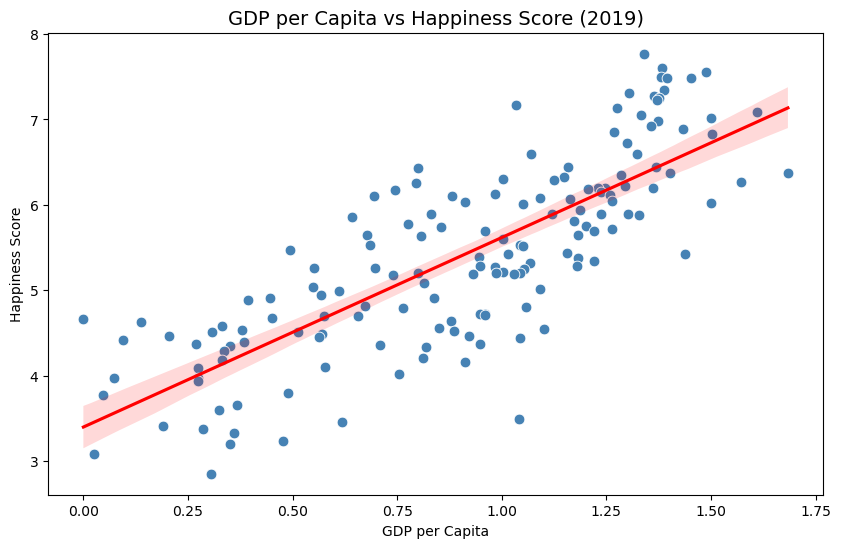

In [24]:
plt.figure(figsize=(10,6))

sns.scatterplot(data=df, x='GDP per capita', y='Score', color='steelblue', s=60)

sns.regplot(data=df, x='GDP per capita', y='Score', scatter=False, color='red')

plt.title('GDP per Capita vs Happiness Score (2019)', fontsize=14)

plt.xlabel('GDP per Capita')
plt.ylabel('Happiness Score')

plt.show()

In [29]:
slope, intercept = np.polyfit(df['GDP per capita'], df['Score'], 1)
df['Predicted'] = slope * df['GDP per capita'] + intercept
df['Residual'] = df['Score'] - df['Predicted']

print('Happier than expected:')
print(df.sort_values('Residual', ascending=False)[['Country or region', 'GDP per capita', 'Score', 'Residual']].head(5))

print('\nLess happy than expected:')
print(df.sort_values('Residual', ascending=True)[['Country or region', 'GDP per capita', 'Score', 'Residual']].head(5))

Happier than expected:
    Country or region  GDP per capita  Score  Residual
11         Costa Rica           1.034  7.167  1.474090
0             Finland           1.340  7.769  1.397337
111           Somalia           0.000  4.668  1.268655
26          Guatemala           0.800  6.436  1.262136
44          Nicaragua           0.694  6.105  1.166260

Less happy than expected:
    Country or region  GDP per capita  Score  Residual
147          Botswana           1.041  3.488 -2.220437
148             Syria           0.619  3.462 -1.310379
116              Iran           1.100  4.548 -1.291308
125              Iraq           1.043  4.437 -1.275874
136             Egypt           0.913  4.166 -1.258514


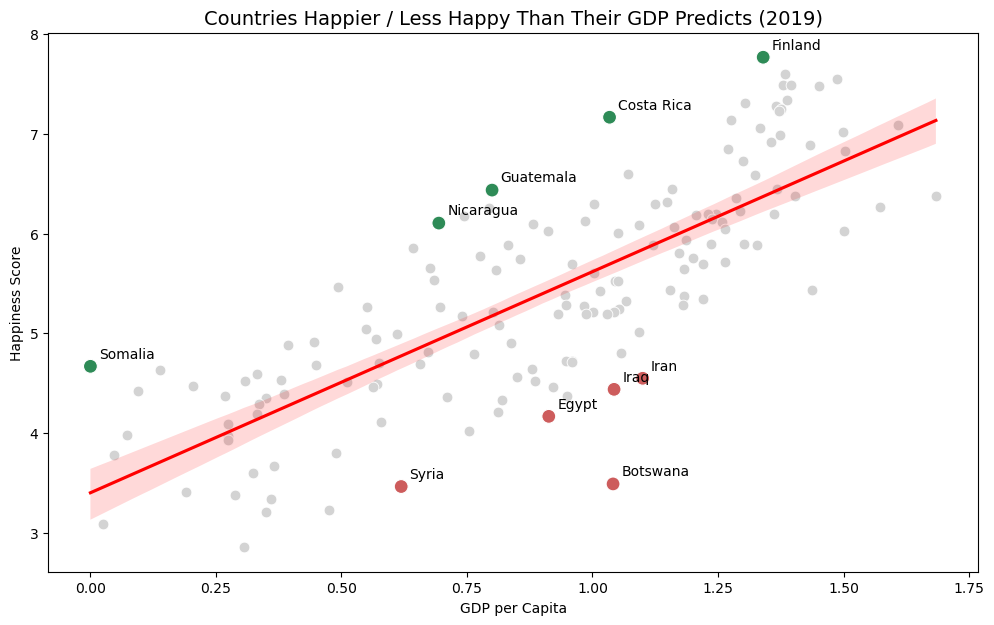

In [32]:
outliers = pd.concat([
    df.sort_values('Residual', ascending=False).head(5),
    df.sort_values('Residual', ascending=True).head(5)
])

plt.figure(figsize=(12, 7))

sns.scatterplot(data=df, x='GDP per capita', y='Score', color='lightgray', s=60)
sns.regplot(data=df, x='GDP per capita', y='Score', scatter=False, color='red')

sns.scatterplot(data=outliers, x='GDP per capita', y='Score', 
                hue=outliers['Residual'] > 0,
               palette={True: 'seagreen', False: 'indianred'},
               s=100, legend=False)

for _, row in outliers.iterrows():
    plt.annotate(row['Country or region'],
                (row['GDP per capita'], row['Score']),
                textcoords='offset points', xytext=(6, 6), fontsize=10)

plt.title('Countries Happier / Less Happy Than Their GDP Predicts (2019)', fontsize=14)
plt.xlabel('GDP per Capita')
plt.ylabel('Happiness Score')

plt.show()

## Key Findings

**1. Most countries are moderately happy.**
Happiness scores range from 2.85 (South Sudan) to 7.77 (Finland), with a mean of ~5.41. Most countries fall between 4 and 6.

**2. The happiest countries are concentrated in Northern Europe.**
Finland, Denmark, Norway, Iceland and the Netherlands lead the ranking, while the least happy countries are mostly in Sub-Saharan Africa and conflict zones.

**3. Wealth, social support and health matter most.**
GDP per capita (r = 0.79), social support (r = 0.78) and healthy life expectancy (r = 0.78) are the strongest correlates of happiness. Generosity shows almost no relationship (r = 0.08).

**4. GDP and health are strongly linked to each other (r = 0.84).**
This makes it hard to separate their individual effects (multicollinearity), which is important for future modelling.

**5. Money is not everything.**
A simple linear regression of Score on GDP reveals clear regional patterns in the residuals:
- **Latin America** (Costa Rica, Guatemala, Nicaragua) is much happier than GDP predicts.
- **The Middle East** (Syria, Iran, Iraq, Egypt) is less happy than GDP predicts, possibly due to conflict and political instability.
- **Botswana** is the strongest negative outlier (residual -2.22).

**6. Data quality note.**
Somalia has a GDP value of exactly 0.000, which is likely missing data rather than a real value. It should be treated with caution.

*Correlation does not imply causation: these findings show associations, not proof that GDP causes happiness.*